**ANOMALY DETECTION OC-SVM**

In [1]:
import digitalhub as dh
import zipfile
import json
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
import shutil

PROJECT_NAME = "floods"
project = dh.get_project(PROJECT_NAME)
print(f"Project: {project.name}")

Project: floods


**SETUP PARAMETERS**

In [2]:
job_name = "dense_v4_0per"
dataset_standard = "Standard"
dataset_anomalies = "Floods_Anomalies_v3_crop_norm"
moco_version = "dense_v4"

parameters = {
    "job_name": job_name,                          
    "dataset_standard": dataset_standard,
    "dataset_anomalies": dataset_anomalies,         
    "moco_version": moco_version, 
    "old_vectors": "", 
    "ocsvm_nu": 0.05,                       
    "ocsvm_gamma": "scale", 
    "min_flood_area": 0.0,
    "moco_attn": False, 
    "dense": True,                
    
    "simple_proj": False,                                                           
    "hidden_channels_dim": 128,
    "pool_grid": 4,
    "moco_dim": 128,
    "moco_k": 4096,
    "moco_m": 0.999,
    "moco_t": 0.07,
    "patch_size": 256,
    "n_images1": 4, "n_channels1": 2,       # sar
    "n_images2": 4, "n_channels2": 10,      # ottico       
    "standardize": True,                    
    "batch_size": 16,
    "workers": 0,

    "do_encoder": True,                        # latente autoencoder + pooling di moco
    "do_pre_proj": True,                        # dopo conv + pooling, prima del proiettore
    "do_proj_raw": True,                       # dopo il proiettore, prima della normalizzazione
    "do_post_proj": True,                      # dopo la normalizzazione (come contrastive_loss)
    "do_dense": True, 
    "do_sim_stats": True,
    
    "pca_encoder": None,
    "pca_pre_proj": None,         
    "pca_proj_raw": None,
    "pca_post_proj": None,


    "whitening": "lw",                         # "pca" | "ledoitwolf"
    "fit_on_train": True,                       # True: fit su tutte le serie di train di moco
    "max_fit_series": 0,                        # 0 = tutte; altrimenti campione casuale (ocsvm lento con molte serie)
}

volumes = [
    {
        "volume_type": "ephemeral",
        "name": "volume-spazio-dati",
        "mount_path": "/data",
        "spec": {"size": "600Gi"}
    }
]

**BUILD ENVIRONMENT**

In [3]:
ocsvm_func = project.new_function(
    name=f'ocsvm_all4',
    kind="python",
    python_version="PYTHON3_10",
    code_src="../../src/",
    handler="anomaly_punti:ad_ocsvm4",
    image="harbor.atlas.fbk.eu/rsde/rsde-platform-floods-floodsimagev3:9b7e2",
)

**TRAINING**

In [ ]:
resources = {"cpu": "4", "mem": "20Gi"}

run_ad = ocsvm_func.run(
    action="job",
    parameters=parameters,
    volumes=volumes,
    resources = resources,
    profile="1xv100",
    local_execution=False,
    wait=True
)

print(f"Run anomaly detection ocsvm: {run_ad.id}")

2026-11-04 20:52:36,908 - dhcore.digitalhub.entities.run._base.entity - INFO - Waiting for run 7cd894ebd18e44068a805e987da1f359 to finish...


2026-11-04 20:52:41,915 - dhcore.digitalhub.entities.run._base.entity - INFO - Waiting for run 7cd894ebd18e44068a805e987da1f359 to finish...
2026-11-04 20:52:46,925 - dhcore.digitalhub.entities.run._base.entity - INFO - Waiting for run 7cd894ebd18e44068a805e987da1f359 to finish...
2026-11-04 20:52:51,941 - dhcore.digitalhub.entities.run._base.entity - INFO - Waiting for run 7cd894ebd18e44068a805e987da1f359 to finish...
2026-11-04 20:52:56,950 - dhcore.digitalhub.entities.run._base.entity - INFO - Waiting for run 7cd894ebd18e44068a805e987da1f359 to finish...
2026-11-04 20:53:01,961 - dhcore.digitalhub.entities.run._base.entity - INFO - Waiting for run 7cd894ebd18e44068a805e987da1f359 to finish...


In [3]:
from IPython.display import display

RESULTS_DIR = f"/tmp/anomaly_results_ocsvm_{job_name}"           # una cartella per job
shutil.rmtree(RESULTS_DIR, ignore_errors=True)

zip_path = project.get_artifact(f"anomaly_results_ocsvm_{job_name}").download(f"{RESULTS_DIR}.zip", overwrite=True)
with zipfile.ZipFile(zip_path) as z:
    z.extractall(RESULTS_DIR)

with open(f"{RESULTS_DIR}/summary.json") as f:
    summary = json.load(f)
punti = list(summary["punti"].keys())                              # solo i punti calcolati in questa run
print(f"job: {job_name} | moco: {summary['moco_version']} | punti: {', '.join(punti)}", "\n")

dati = {}          # punto -> (results, df), per i grafici
righe = []

for punto in punti:
    with open(f"{RESULTS_DIR}/{punto}/anomaly_results.json") as f:
        results = json.load(f)
    df = pd.read_csv(f"{RESULTS_DIR}/{punto}/scores.csv")
    dati[punto] = (results, df)

    score_normal = df[df.label == 0]["score"]
    score_anom = df[df.label == 1]["score"]

    print(f"===== {punto} =====")
    print(f"n_fit: {results['n_fit']} | n_thr: {results['n_thr']} | n_normali: {results['n_normali']} | n_anomale: {results['n_anomale']}")
    print(f"whitening: {results.get('whitening', 'pca')} | componenti: {results['n_componenti']} | shrinkage: {results.get('shrinkage')}")
    print(f"nu: {results['ocsvm']['nu']} | gamma: {results['ocsvm']['gamma']} | dim: {results['ocsvm']['dim']} | frac_outside_fit: {results['ocsvm']['frac_outside_fit']:.3f}")
    print(f"min_flood_area = {results['min_flood_area']:.3f}")
    print(f"score normali: {score_normal.mean():.4f} ± {score_normal.std():.4f}")
    print(f"score anomale: {score_anom.mean():.4f} ± {score_anom.std():.4f}")
    print(f"AUROC: {results['auroc']:.3f}")

    display(pd.DataFrame(results["rules"]).T)                      # regole del punto

    righe.append({"punto": punto, "componenti": results["n_componenti"],
                  "shrinkage": results.get("shrinkage"), "AUROC": results["auroc"]})

# confronto tra i punti
print("===== CONFRONTO =====")
pd.DataFrame(righe).set_index("punto").round(3)

job: dense_v4_0per | moco: dense_v4 | punti: encoder, pre_proj, proj_raw, post_proj, dense, sim_stats 

===== encoder =====
n_fit: 19893 | n_thr: 2572 | n_normali: 2402 | n_anomale: 2402
whitening: lw | componenti: 512 | shrinkage: 0.0024228534744755678
nu: 0.05 | gamma: scale | dim: 512 | frac_outside_fit: 0.050
min_flood_area = 0.000
score normali: 26.7015 ± 17.4207
score anomale: 1.7694 ± 14.8177
AUROC: 0.855


,soglia,TP,FP,FN,TN,FA_rate,MA_rate,REC,PREC,F1
FA 5%,-4.092149,978.0,107.0,1424.0,2295.0,0.044546,0.592839,0.407161,0.901382,0.560941
FA 10%,1.884100,1338.0,196.0,1064.0,2206.0,0.081599,0.442964,0.557036,0.872229,0.679878
FA 15%,6.747321,1556.0,325.0,846.0,2077.0,0.135304,0.352206,0.647794,0.827220,0.726594
FA 20%,10.229344,1711.0,451.0,691.0,1951.0,0.187760,0.287677,0.712323,0.791397,0.749781
FA 25%,13.568295,1855.0,571.0,547.0,1831.0,0.237719,0.227727,0.772273,0.764633,0.768434
FA 30%,16.678342,1954.0,710.0,448.0,1692.0,0.295587,0.186511,0.813489,0.733483,0.771417


===== pre_proj =====
n_fit: 19893 | n_thr: 2572 | n_normali: 2402 | n_anomale: 2402
whitening: lw | componenti: 4096 | shrinkage: 0.013271575640817459
nu: 0.05 | gamma: scale | dim: 4096 | frac_outside_fit: 0.049
min_flood_area = 0.000
score normali: 20.1968 ± 17.4449
score anomale: 2.2620 ± 14.5195
AUROC: 0.780


,soglia,TP,FP,FN,TN,FA_rate,MA_rate,REC,PREC,F1
FA 5%,-11.750444,507.0,81.0,1895.0,2321.0,0.033722,0.788926,0.211074,0.862245,0.339130
FA 10%,-6.802547,872.0,208.0,1530.0,2194.0,0.086595,0.636969,0.363031,0.807407,0.500862
FA 15%,-2.251756,1142.0,324.0,1260.0,2078.0,0.134888,0.524563,0.475437,0.778990,0.590486
FA 20%,1.838191,1337.0,442.0,1065.0,1960.0,0.184013,0.443381,0.556619,0.751546,0.639560
FA 25%,5.724608,1509.0,556.0,893.0,1846.0,0.231474,0.371774,0.628226,0.730751,0.675621
FA 30%,9.365656,1649.0,687.0,753.0,1715.0,0.286012,0.313489,0.686511,0.705908,0.696074


===== proj_raw =====
n_fit: 19893 | n_thr: 2572 | n_normali: 2402 | n_anomale: 2402
whitening: lw | componenti: 256 | shrinkage: 0.013341493668565914
nu: 0.05 | gamma: scale | dim: 256 | frac_outside_fit: 0.055
min_flood_area = 0.000
score normali: 8.4906 ± 4.8062
score anomale: 4.7870 ± 4.5372
AUROC: 0.714


,soglia,TP,FP,FN,TN,FA_rate,MA_rate,REC,PREC,F1
FA 5%,-0.971337,291.0,90.0,2111.0,2312.0,0.037469,0.878851,0.121149,0.763780,0.209127
FA 10%,0.302783,513.0,209.0,1889.0,2193.0,0.087011,0.786428,0.213572,0.710526,0.328425
FA 15%,1.759471,750.0,327.0,1652.0,2075.0,0.136137,0.687760,0.312240,0.696379,0.431158
FA 20%,3.528374,1050.0,449.0,1352.0,1953.0,0.186928,0.562864,0.437136,0.700467,0.538324
FA 25%,5.042077,1300.0,583.0,1102.0,1819.0,0.242714,0.458784,0.541216,0.690388,0.606768
FA 30%,6.030471,1447.0,692.0,955.0,1710.0,0.288093,0.397585,0.602415,0.676484,0.637305


... (4 outputs left out)

===== sim_stats =====
n_fit: 19893 | n_thr: 2572 | n_normali: 2402 | n_anomale: 2402
whitening: lw | componenti: 6 | shrinkage: 0.0009736666416658366
nu: 0.05 | gamma: scale | dim: 6 | frac_outside_fit: 0.050
min_flood_area = 0.000
score normali: 8.5979 ± 4.8182
score anomale: 8.0559 ± 5.1360
AUROC: 0.538


,soglia,TP,FP,FN,TN,FA_rate,MA_rate,REC,PREC,F1
FA 5%,-1.142390,135.0,108.0,2267.0,2294.0,0.044963,0.943797,0.056203,0.555556,0.102079
FA 10%,3.087092,283.0,240.0,2119.0,2162.0,0.099917,0.882182,0.117818,0.541109,0.193504
FA 15%,4.972236,431.0,375.0,1971.0,2027.0,0.156120,0.820566,0.179434,0.534739,0.268703
FA 20%,6.143897,563.0,483.0,1839.0,1919.0,0.201082,0.765612,0.234388,0.538241,0.326566
FA 25%,6.961602,676.0,576.0,1726.0,1826.0,0.239800,0.718568,0.281432,0.539936,0.370005
FA 30%,7.696001,792.0,697.0,1610.0,1705.0,0.290175,0.670275,0.329725,0.531901,0.407093


===== CONFRONTO =====


,componenti,shrinkage,AUROC
punto,,,
encoder,512,0.002,0.855
pre_proj,4096,0.013,0.780
proj_raw,256,0.013,0.714
post_proj,256,0.002,0.712
dense,4096,0.002,0.735
sim_stats,6,0.001,0.538


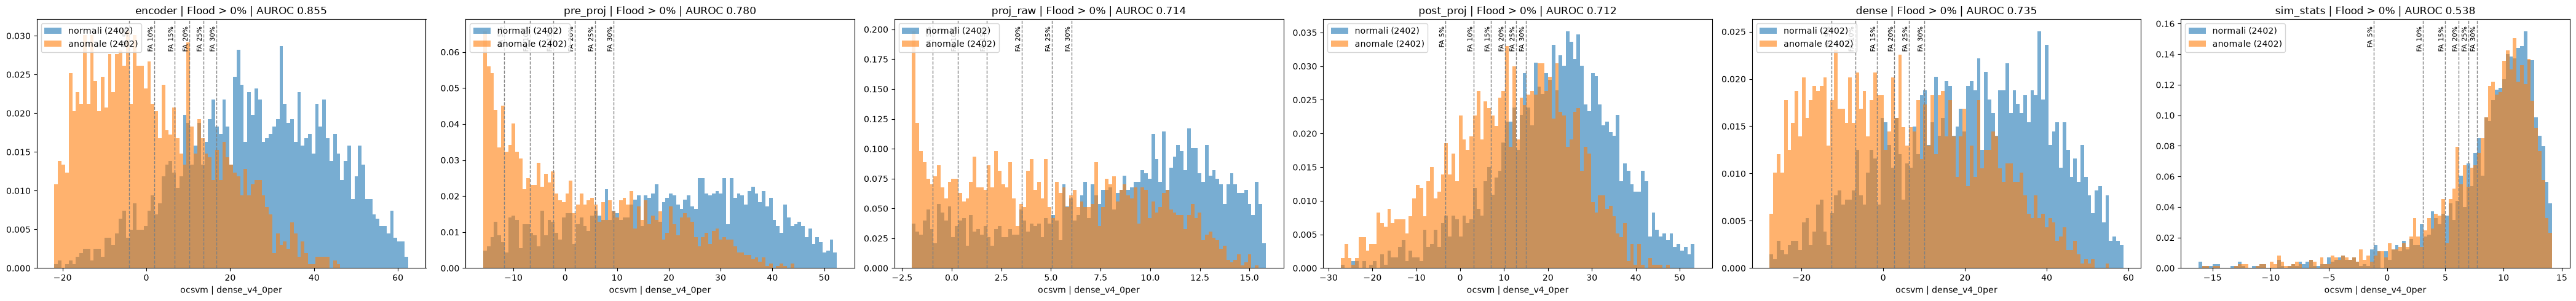

In [4]:
fig, axes = plt.subplots(1, len(punti), figsize=(7 * len(punti), 5), squeeze=False)

for ax, punto in zip(axes[0], punti):
    results, df = dati[punto]
    score_normal = df[df.label == 0]["score"]
    score_anom = df[df.label == 1]["score"]

    lo, hi = np.quantile(df.score, [0.005, 0.995])
    bins = np.linspace(lo, hi, 100)

    ax.hist(score_normal, bins=bins, alpha=0.6, density=True, label=f"normali ({len(score_normal)})")
    ax.hist(score_anom, bins=bins, alpha=0.6, density=True, label=f"anomale ({len(score_anom)})")

    for nome, r in results["rules"].items():
        if lo <= r["soglia"] <= hi:
            ax.axvline(x=r["soglia"], color="gray", linestyle="--", linewidth=1)
            ax.text(r["soglia"], ax.get_ylim()[1] * 0.97, nome.split("(")[-1].rstrip(")"),
                    rotation=90, va="top", ha="right", fontsize=8)

    ax.set_xlabel(f"ocsvm | {job_name}")
    ax.legend(loc="upper left")
    ax.set_title(f"{punto} | Flood > {results['min_flood_area']:.0f}% | AUROC {results['auroc']:.3f}")

plt.tight_layout()
plt.show()

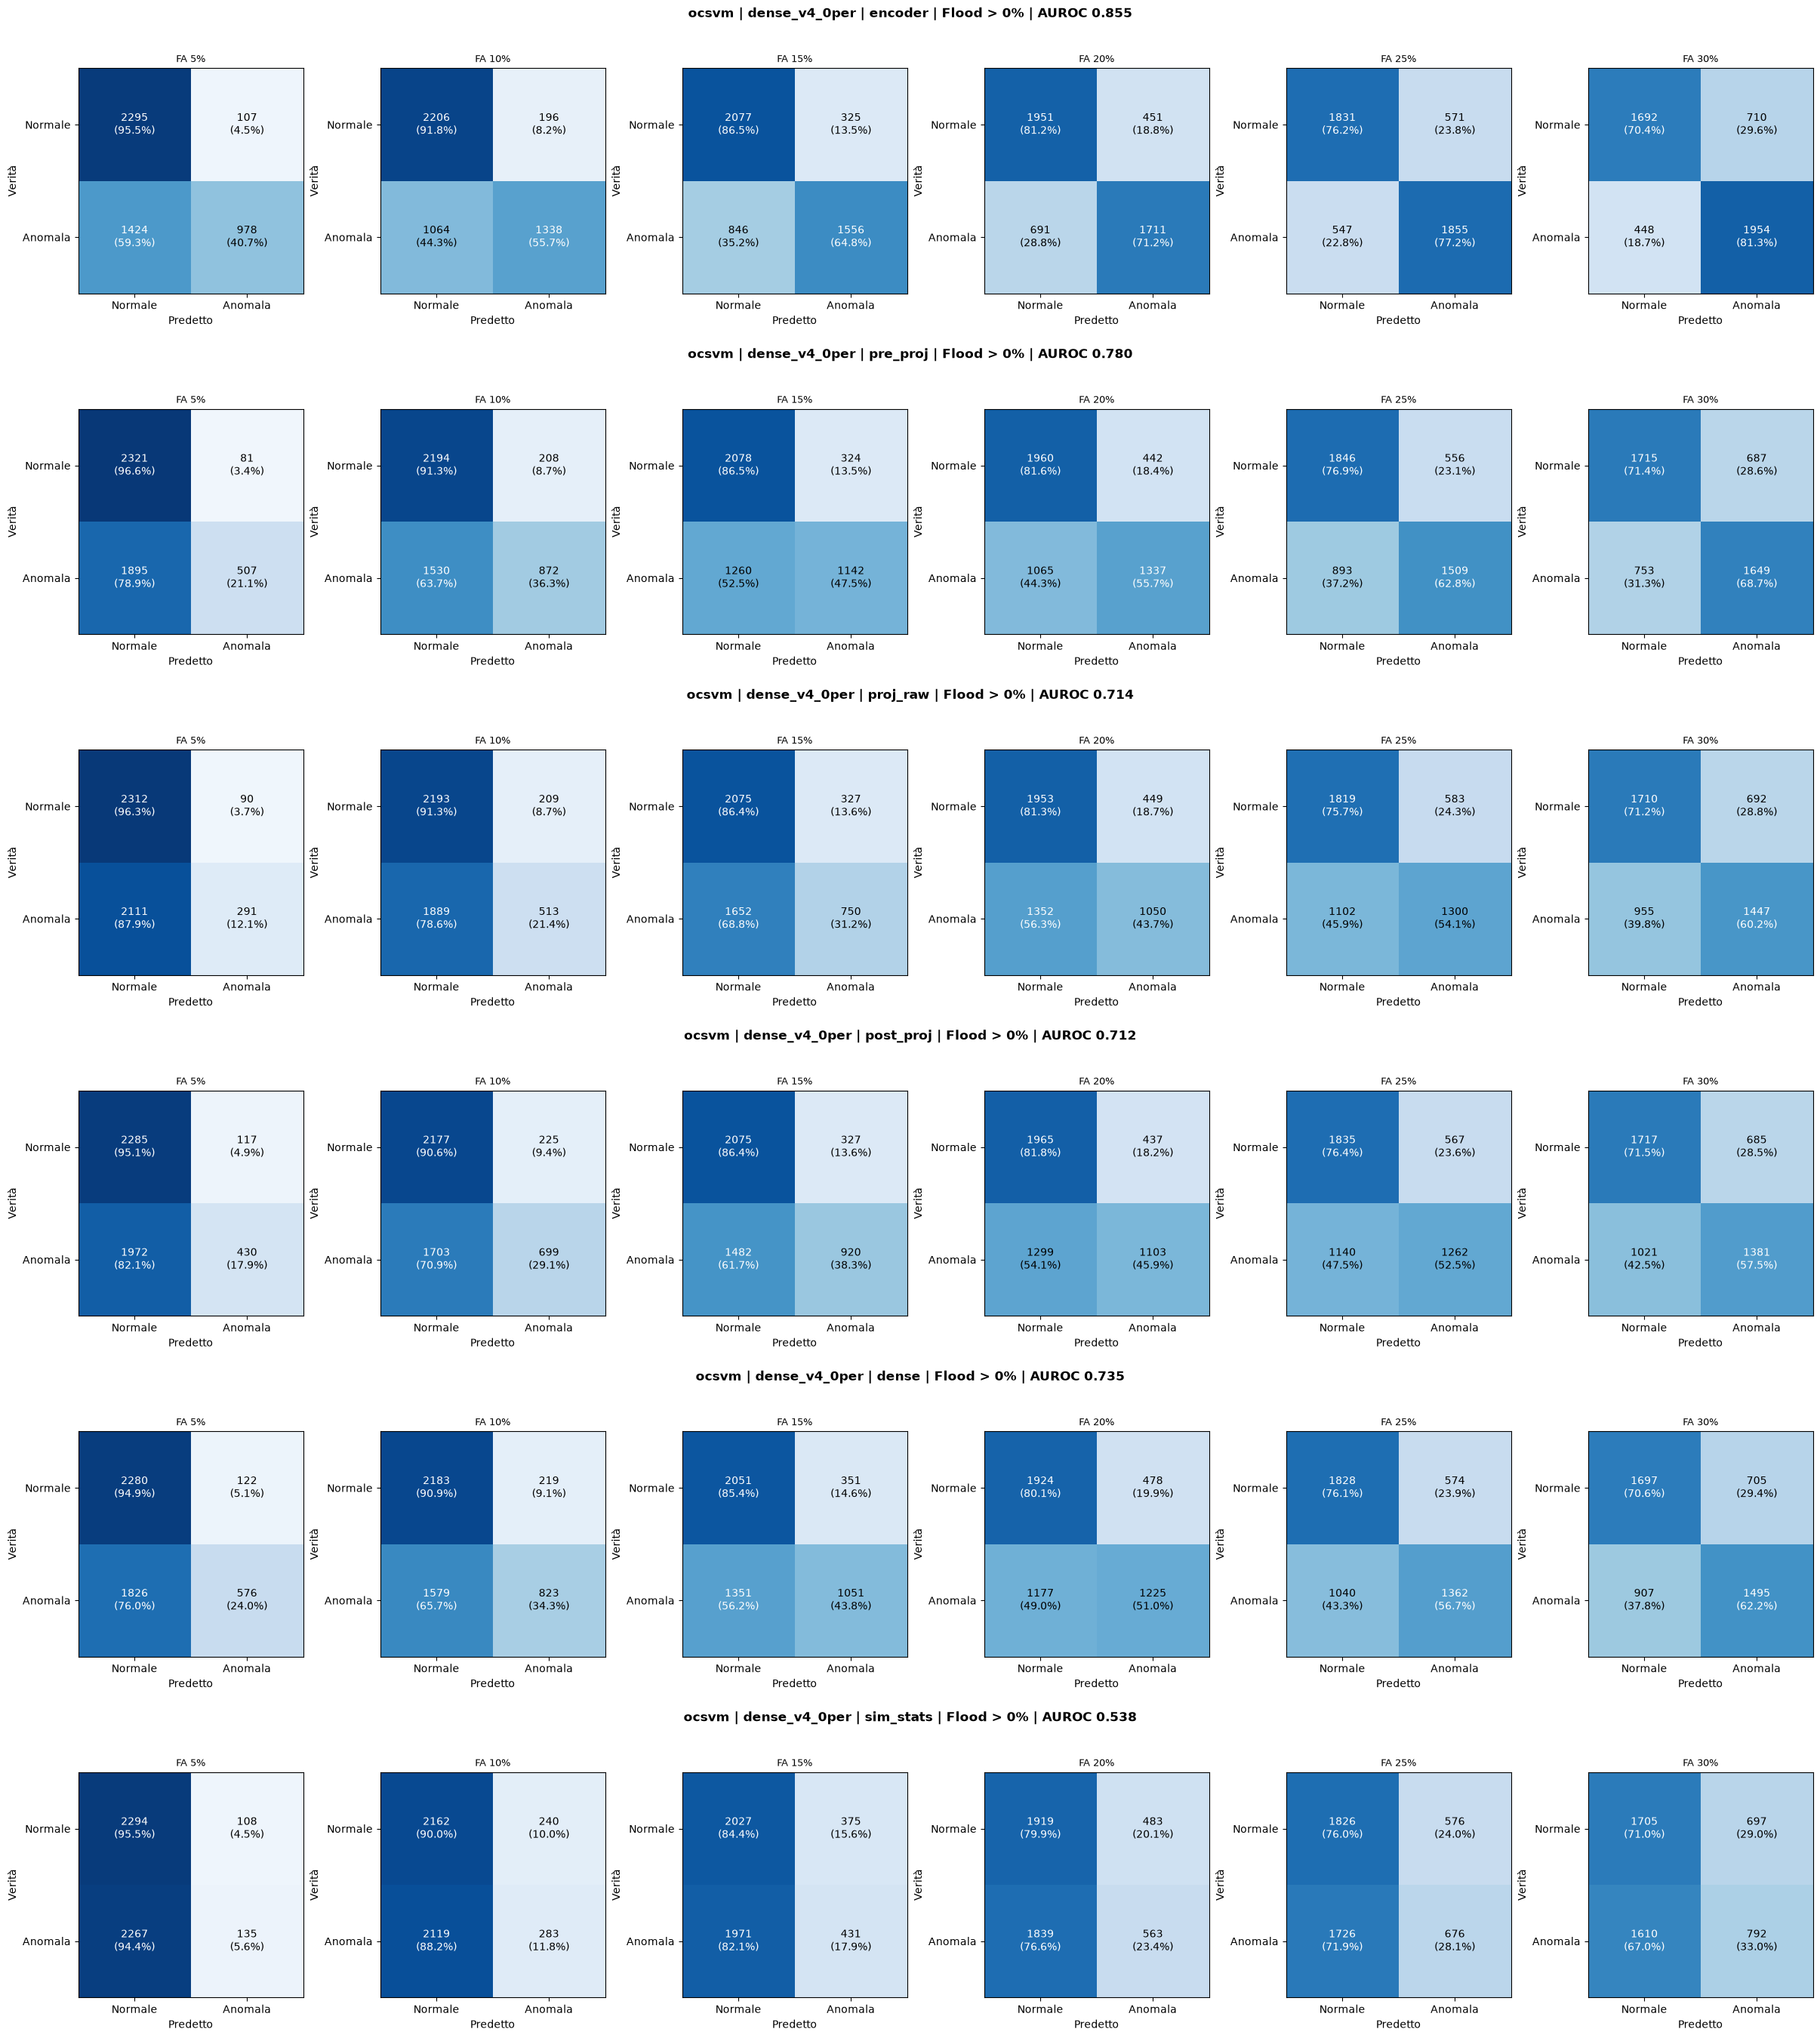

In [5]:
n_cols = max(len(dati[p][0]["rules"]) for p in punti)

fig = plt.figure(figsize=(4 * n_cols, 4.5 * len(punti)), layout="constrained")
subfigs = np.atleast_1d(fig.subfigures(len(punti), 1))

for sfig, punto in zip(subfigs, punti):
    results, _ = dati[punto]
    rules = results["rules"]
    axes_row = sfig.subplots(1, n_cols, squeeze=False)[0]

    for ax, (nome, r) in zip(axes_row, rules.items()):
        mat = np.array([[r["TN"], r["FP"]],
                        [r["FN"], r["TP"]]])
        mat_pct = mat / mat.sum(axis=1, keepdims=True) * 100

        ax.imshow(mat_pct, cmap="Blues", vmin=0, vmax=100)
        ax.set_xticks([0, 1]); ax.set_xticklabels(["Normale", "Anomala"])
        ax.set_yticks([0, 1]); ax.set_yticklabels(["Normale", "Anomala"])
        ax.set_xlabel("Predetto"); ax.set_ylabel("Verità")
        ax.set_title(nome, fontsize=9)

        for i in range(2):
            for j in range(2):
                color = "white" if mat_pct[i, j] > 55 else "black"
                ax.text(j, i, f"{int(mat[i, j])}\n({mat_pct[i, j]:.1f}%)",
                        ha="center", va="center", color=color, fontsize=10)

    for ax in axes_row[len(rules):]:
        ax.axis("off")

    sfig.suptitle(f"ocsvm | {job_name} | {punto} | Flood > {results['min_flood_area']:.0f}% | AUROC {results['auroc']:.3f}",
                  fontsize=12, fontweight="bold")

plt.show()

In [ ]:
from sklearn.metrics import roc_auc_score
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.covariance import LedoitWolf

punto = "pre_proj"

# verifica dei risultati caricati
with open(f"{RESULTS_DIR}/summary.json") as f:
    summary = json.load(f)
with open(f"{RESULTS_DIR}/{punto}/anomaly_results.json") as f:
    info = json.load(f)

print(f"cartella:      {RESULTS_DIR}")
print(f"job:           {summary['job_name']} | moco: {summary['moco_version']} | dataset anomalie: {summary['dataset_anomalies']}")
print(f"fit_on_train:  {summary.get('fit_on_train')} | punti nella run: {', '.join(summary['punti'].keys())}")
print(f"punto:         {info['feature_point']} | min_flood_area: {info['min_flood_area']}")
print(f"serie:         fit {info['n_fit']} | thr {info['n_thr']} | normali {info['n_normali']} | anomale {info['n_anomale']}")
print(f"AUROC nel job: {info['auroc']:.3f} ({info['metodo']}, whitening {info.get('whitening', 'pca')}, {info['n_componenti']} componenti)", "\n")

E = np.load(f"{RESULTS_DIR}/{punto}/embeddings.npz")
cat = lambda g: np.concatenate([E[f"{g}_q"], E[f"{g}_k"]], axis=1).astype(np.float64)

w = {g: cat(g) for g in ("fit", "thr", "normal", "anom")}
print("forme:", {g: v.shape for g, v in w.items()}, "\n")

scaler = StandardScaler().fit(w["fit"])
w = {g: scaler.transform(v) for g, v in w.items()}

pca = PCA(whiten=True).fit(w["fit"])                     # una sola PCA con tutte le componenti
z = {g: pca.transform(v) for g, v in w.items()}


rng = np.random.default_rng(0)
ia = rng.permutation(len(z["anom"]));   a_val, a_test = ia[: len(ia) // 2], ia[len(ia) // 2:]
i_n = rng.permutation(len(z["normal"])); n_val, n_test = i_n[: len(i_n) // 2], i_n[len(i_n) // 2:]

def auroc(md, n_idx, a_idx):
    y = np.r_[np.zeros(len(n_idx)), np.ones(len(a_idx))]
    return roc_auc_score(y, np.r_[md["normal"][n_idx], md["anom"][a_idx]])

righe = []
for k in (32, 64, 128, 256, 512, 768, 1024, 1536, 2048, 3072, 4096):
    if k > z["fit"].shape[1]:
        break
    md = {g: (v[:, :k] ** 2).sum(1) for g, v in z.items()}         
    righe.append({
        "k": k,
        "thr/fit": md["thr"].mean() / md["fit"].mean(),  
        "AUROC": auroc(md, n_val, a_val),                
    })


lw = LedoitWolf().fit(w["fit"])
md = {g: lw.mahalanobis(v) for g, v in w.items()}                   
righe.append({
    "k": f"LW ({w['fit'].shape[1]})",
    "thr/fit": md["thr"].mean() / md["fit"].mean(),
    "AUROC": auroc(md, n_val, a_val),
})
print(f"Ledoit-Wolf shrinkage: {lw.shrinkage_:.3f}")

scelta = pd.DataFrame(righe).set_index("k")
print(scelta.round(3))

cartella:      /tmp/anomaly_results_ocsvm_dense_v1_0per
job:           dense_v1_0per | moco: dense_v1 | dataset anomalie: Floods_Anomalies_v3_crop_norm
fit_on_train:  True | punti nella run: encoder, pre_proj, proj_raw, post_proj, dense, sim_stats
punto:         pre_proj | min_flood_area: 0.0
serie:         fit 19893 | thr 2572 | normali 2402 | anomale 2402
AUROC nel job: 0.801 (ocsvm, whitening lw, 4096 componenti) 

forme: {'fit': (19893, 4096), 'thr': (2572, 4096), 'normal': (2402, 4096), 'anom': (2402, 4096)} 

Ledoit-Wolf shrinkage: 0.013
           rapporto soglia/fit  AUROC validazione
k                                                
32                       1.097              0.655
64                       1.071              0.687
128                      1.051              0.707
256                      1.034              0.728
512                      1.026              0.749
768                      1.024              0.758
1024                     1.030              0.765
